In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA  #imp
from sklearn.naive_bayes import GaussianNB #imp
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 
print('*')

*


In [5]:
df = pd.read_csv('../wine_dataset.csv')
X = df.drop('target', axis=1)
y = df['target']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
#Standardization needed because PCA is variance-based; features on
# different scales (e.g. proline ~1000 vs ash ~2) would dominate the
# principal components purely due to magnitude, not actual importance.

In [6]:
pca_full = PCA()
pca_full.fit(X_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

print("Explained variance ratio:", explained_var)
print("Cumulative variance:", cum_var)

Explained variance ratio: [0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]
Cumulative variance: [0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


In [10]:
for n in [2, 3, 4, 5, 6, 7, 8, 9,10]:
    pca_n = PCA(n_components=n)
    pca_n.fit(X_scaled)
    print(f"n_components={n} -> variance retained: {sum(pca_n.explained_variance_ratio_):.4f}")

n_90 = np.argmax(cum_var >= 0.90) + 1
print(f"Components needed for >=90% variance: {n_90}")


n_components=2 -> variance retained: 0.5541
n_components=3 -> variance retained: 0.6653
n_components=4 -> variance retained: 0.7360
n_components=5 -> variance retained: 0.8016
n_components=6 -> variance retained: 0.8510
n_components=7 -> variance retained: 0.8934
n_components=8 -> variance retained: 0.9202
n_components=9 -> variance retained: 0.9424
n_components=10 -> variance retained: 0.9617
Components needed for >=90% variance: 8


In [11]:
pca = PCA(n_components=n_90)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y
)

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

Accuracy: 0.9722
Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



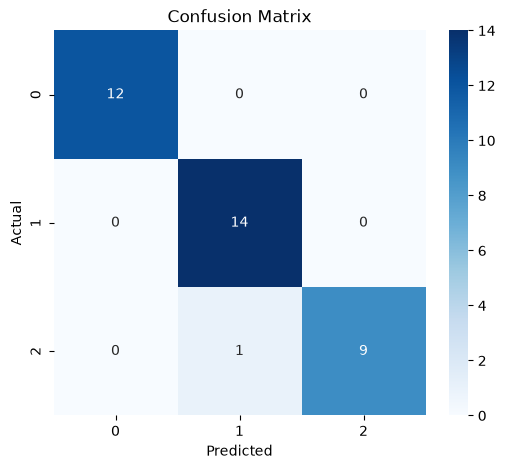

In [12]:
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {acc:.4f}")
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", report)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

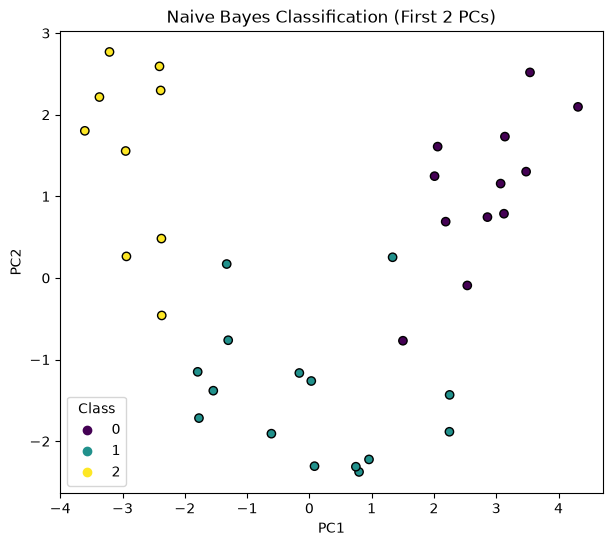

In [14]:
plt.figure(figsize=(7,6))
scatter = plt.scatter(X_test[:,0], X_test[:,1], c=y_pred, cmap='viridis', edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Naive Bayes Classification (First 2 PCs)')
plt.legend(*scatter.legend_elements(), title="Class")
plt.show()